# Lab 4 — DINO on Colab

This notebook contains the Colab setup followed by all cells from `04_dino_starter.ipynb`.

1. Select **Runtime → Change runtime type → T4 GPU**.
2. Check the repository and branch below, then run the setup cells.
3. Continue through the main notebook cells with **Shift+Enter**. You can run the variants individually.

Setup fetches only `lab4`. The experiment code imports its supporting modules from
that checkout. Figures and completed-run checkpoints are saved in its `lab4` directory.


In [1]:
# Uncomment the following line to mount your Google Drive for saving figures and checkpoints.
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
from pathlib import Path

REPO = "https://github.com/typsoon/pattern-recognition.git"
BRANCH = "main"  # Change to yours in your branch during experiment run in Colab (if needed).
REPO_DIR = Path("/content/pattern-recognition-lab4")
LAB_DIR = REPO_DIR / "lab4"


In [3]:
%%bash -s "$REPO" "$BRANCH" "$REPO_DIR"
set -euo pipefail

# Receive the Python configuration as quoted positional arguments.
lab4_repo="$1"
lab4_branch="$2"
lab4_repo_dir="$3"

if [ ! -d "$lab4_repo_dir/.git" ]; then
    # Defer file downloads until sparse checkout selects lab4.
    git clone --filter=blob:none --no-checkout --single-branch \
        --branch "$lab4_branch" "$lab4_repo" "$lab4_repo_dir"
else
    # Refresh the selected remote branch while preserving local working files.
    git -C "$lab4_repo_dir" fetch origin \
        "$lab4_branch:refs/remotes/origin/$lab4_branch"
fi

# Check out the lab files and accept only a fast-forward branch update.
git -C "$lab4_repo_dir" sparse-checkout set --cone lab4
git -C "$lab4_repo_dir" checkout "$lab4_branch"
git -C "$lab4_repo_dir" merge --ff-only "origin/$lab4_branch"
git -C "$lab4_repo_dir" log -1 --oneline


Your branch is up to date with 'origin/main'.
Already up to date.
1f51226 adjust the main notebook


Already on 'main'


In [4]:
# Install data and plotting dependencies while keeping Colab's CUDA-enabled PyTorch.
%pip install -q numpy pandas pillow matplotlib pyarrow


In [5]:
%matplotlib inline

import os
import sys
import torch

# Bash runs separately; set the Python kernel's working directory and import path here.
os.chdir(LAB_DIR)
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))

assert torch.cuda.is_available(), (
    "Select Runtime → Change runtime type → T4 GPU, then rerun the setup cells."
)
print("GPU:", torch.cuda.get_device_name(0))
print("Working directory:", LAB_DIR)


GPU: Tesla T4
Working directory: /content/pattern-recognition-lab4/lab4


# **Task 4 — DINO**: break it, then fix it your way

This week's seminar was about [DINO](https://openaccess.thecvf.com/content/ICCV2021/html/Caron_Emerging_Properties_in_Self-Supervised_Vision_Transformers_ICCV_2021_paper.html). It has no labels and no negatives, so nothing in its loss forbids giving the same output to every image. Centering and sharpening stop this collapse, and the lecture showed how with schematic figures. Here you measure the real thing.

This notebook gives you CIFAR-10, a tiny ViT, a **working DINO loop** and a **fixed evaluation**. The task is on the card.

<details>
<summary>Reach out here if you have any problems</summary>
Taras Kutsyk — taras.kutsyk@doctoral.uj.edu.pl
</details>

## Setup
Run this notebook from the lab4 directory using a GPU-enabled environment.

Implementation lives in `network.py`, `training.py`, `evaluation.py`,
`common.py`, `checkpointing.py`, and `plots.py`. This notebook runs the experiments.

In [6]:
from functools import partial

import matplotlib.pyplot as plt

from checkpointing import cached_train_dino
from common import load, normalize
from evaluation import knn_eval, present_baselines, present_the_outcome
from network import DINONetwork
from plots import plot_variants
from training import train_dino

In [7]:
# Load each split once; normalization is applied during training and evaluation.
train_images, train_labels = load("train")
test_images, test_labels = load("test")
print("train", train_images.shape, "test", test_images.shape)

# Bind datasets once, keeping experiment options and checkpoint names concise.
train = partial(train_dino, train_images, train_labels)
evaluate = partial(
    knn_eval,
    train_images=train_images,
    train_labels=train_labels,
    test_images=test_images,
    test_labels=test_labels,
)

train torch.Size([50000, 3, 32, 32]) test torch.Size([10000, 3, 32, 32])


## Baselines
Report the fixed raw-pixel and untrained-network k-NN baselines.
Use `val_knn()` in `evaluation.py` for tuning, and the fixed test evaluation for final results.

In [8]:
present_baselines(train_images, train_labels, test_images, test_labels)

parameters: 808064
raw pixels, k-NN accuracy: 0.4568
untrained network, k-NN accuracy: 0.32


## Reference run
Full DINO uses centering and sharpening. Completed runs load from `checkpoints/`.

In [9]:
full = cached_train_dino(train, DINONetwork)
present_the_outcome(full, evaluate)

epoch  1 (  12s): entropy 5.87, batch entropy 6.69, KL 0.580
epoch  2 (  23s): entropy 5.46, batch entropy 6.51, KL 0.634
epoch  3 (  35s): entropy 5.09, batch entropy 6.37, KL 0.690
epoch  4 (  46s): entropy 4.64, batch entropy 6.19, KL 0.762
epoch  5 (  59s): entropy 4.34, batch entropy 6.14, KL 0.770, val_knn 0.3728
epoch  6 (  71s): entropy 4.04, batch entropy 6.09, KL 0.960
epoch  7 (  83s): entropy 3.62, batch entropy 5.92, KL 1.003
epoch  8 (  95s): entropy 3.53, batch entropy 6.03, KL 1.056
epoch  9 ( 107s): entropy 3.22, batch entropy 5.97, KL 1.143
epoch 10 ( 120s): entropy 2.89, batch entropy 5.86, KL 1.239, val_knn 0.4228
epoch 11 ( 132s): entropy 2.73, batch entropy 5.88, KL 1.338
epoch 12 ( 144s): entropy 2.58, batch entropy 5.89, KL 1.450
epoch 13 ( 156s): entropy 2.46, batch entropy 5.86, KL 1.504
epoch 14 ( 168s): entropy 2.18, batch entropy 5.81, KL 1.597
epoch 15 ( 181s): entropy 2.12, batch entropy 5.79, KL 1.669, val_knn 0.4536
epoch 16 ( 193s): entropy 1.93, batch

INFO: Saved /content/pattern-recognition-lab4/lab4/checkpoints/dino.pt


student k-NN: 0.4876 | teacher k-NN: 0.4817
peak GPU memory, GB: 2.6


## Part 1: remove centering and sharpening
Each cell runs or loads one variant, then reports its student and teacher accuracy.

In [10]:
no_center = cached_train_dino(train, DINONetwork, center=False)
present_the_outcome(no_center, evaluate)

epoch  1 (  12s): entropy 4.92, batch entropy 5.39, KL 0.350
epoch  2 (  24s): entropy 2.73, batch entropy 3.33, KL 0.385
epoch  3 (  36s): entropy 1.20, batch entropy 1.98, KL 0.440
epoch  4 (  48s): entropy 0.85, batch entropy 1.73, KL 0.470
epoch  5 (  61s): entropy 0.67, batch entropy 1.56, KL 0.405, val_knn 0.3538
epoch  6 (  73s): entropy 0.60, batch entropy 1.48, KL 0.419
epoch  7 (  85s): entropy 0.52, batch entropy 1.49, KL 0.427
epoch  8 (  97s): entropy 0.49, batch entropy 1.38, KL 0.388
epoch  9 ( 109s): entropy 0.44, batch entropy 1.35, KL 0.369
epoch 10 ( 122s): entropy 0.41, batch entropy 1.33, KL 0.368, val_knn 0.3688
epoch 11 ( 134s): entropy 0.37, batch entropy 1.28, KL 0.379
epoch 12 ( 146s): entropy 0.35, batch entropy 1.24, KL 0.393
epoch 13 ( 157s): entropy 0.31, batch entropy 1.19, KL 0.331
epoch 14 ( 169s): entropy 0.28, batch entropy 1.16, KL 0.324
epoch 15 ( 183s): entropy 0.26, batch entropy 1.12, KL 0.344, val_knn 0.3916
epoch 16 ( 195s): entropy 0.25, batch

INFO: Saved /content/pattern-recognition-lab4/lab4/checkpoints/dino_center=False.pt


student k-NN: 0.4152 | teacher k-NN: 0.4097
peak GPU memory, GB: 2.6


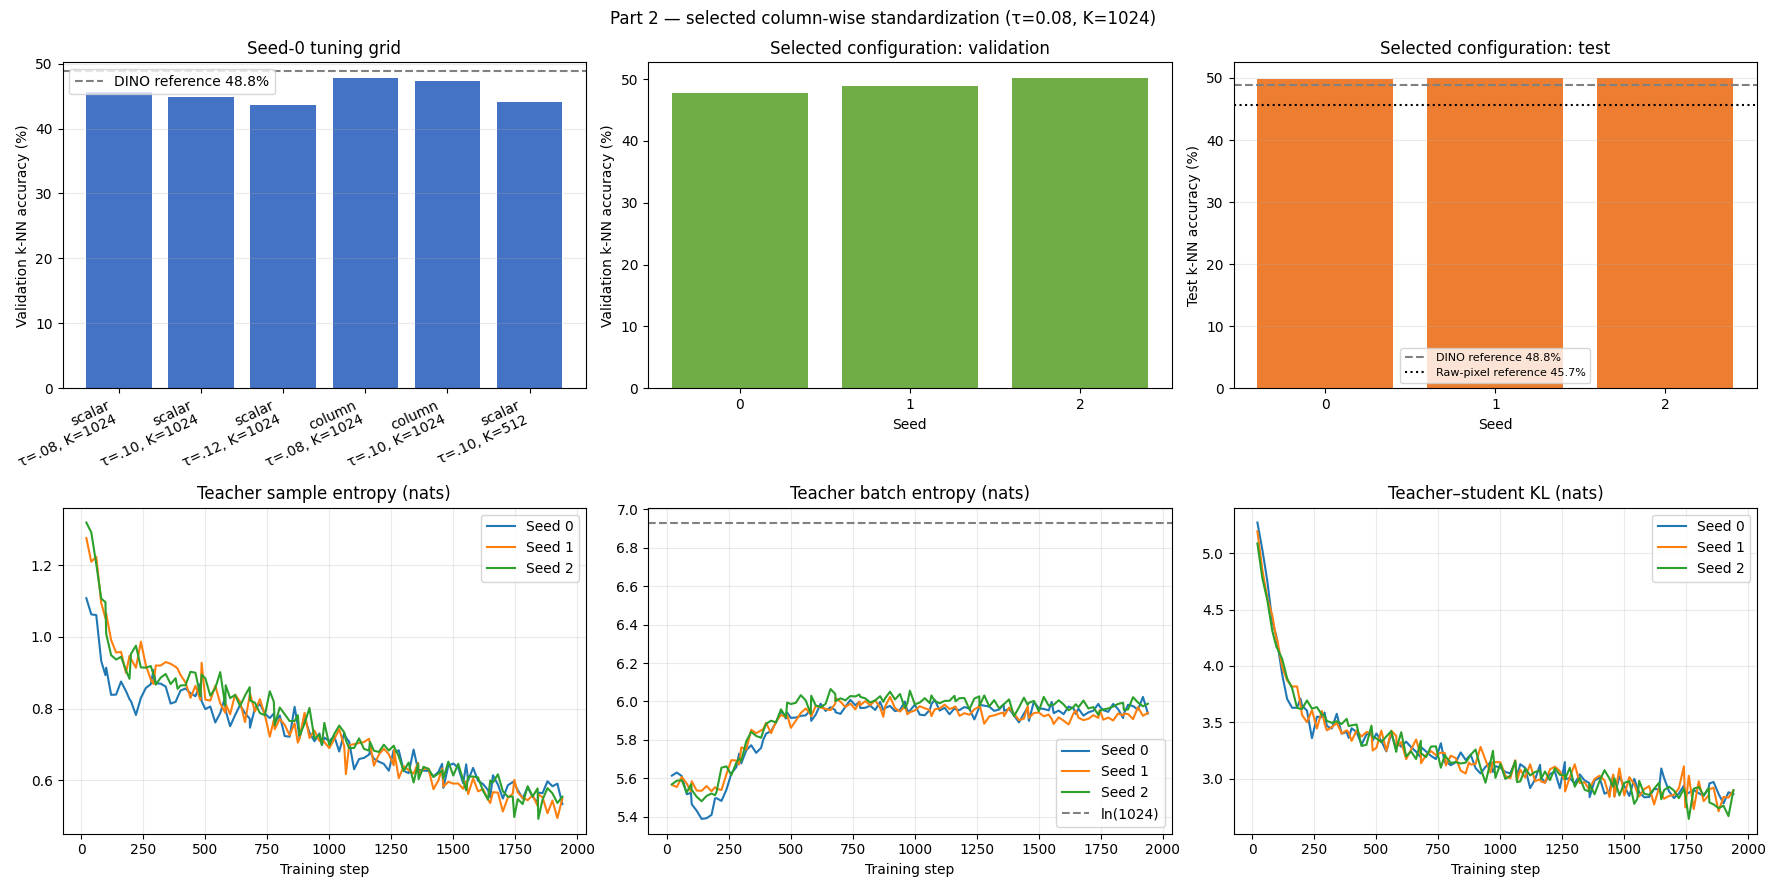

In [16]:
from pathlib import Path
import json
import matplotlib.pyplot as plt

# Finds the saved histories; edit this path if your artifacts are stored elsewhere.
candidates = [
    Path("/content/drive/MyDrive/dino_task4/checkpoints"),
    Path("/content/pattern-recognition-lab4/lab4/runs/fix-standardize/checkpoints"),
    Path("/content/pattern-recognition-lab4/lab4/checkpoints"),
]
CHECKPOINT_DIR = next(
    (path for path in candidates
     if (path / "standardize_best_seed0_history.json").is_file()),
    None,
)
if CHECKPOINT_DIR is None:
    raise FileNotFoundError(
        "Could not find standardize_best_seed0_history.json. "
        "Set CHECKPOINT_DIR to the folder containing the saved histories."
    )

tuning = {
    "scalar\nτ=.08, K=1024": 0.4560,
    "scalar\nτ=.10, K=1024": 0.4484,
    "scalar\nτ=.12, K=1024": 0.4356,
    "column\nτ=.08, K=1024": 0.4780,
    "column\nτ=.10, K=1024": 0.4736,
    "scalar\nτ=.10, K=512": 0.4410,
}
val_by_seed = {0: 0.4780, 1: 0.4888, 2: 0.5020}
test_by_seed = {0: 0.4976, 1: 0.4996, 2: 0.5002}

histories = {}
for seed in (0, 1, 2):
    path = CHECKPOINT_DIR / f"standardize_best_seed{seed}_history.json"
    if not path.is_file():
        raise FileNotFoundError(f"Missing selected-run history: {path}")
    with path.open(encoding="utf-8") as file:
        histories[seed] = json.load(file)

fig, axes = plt.subplots(2, 3, figsize=(18, 9))

# Seed-0 tuning scores: this is what selected the configuration.
labels = list(tuning)
scores = [100 * tuning[label] for label in labels]
axes[0, 0].bar(range(len(labels)), scores, color="#4472C4")
axes[0, 0].set_xticks(range(len(labels)), labels, rotation=25, ha="right")
axes[0, 0].set_ylabel("Validation k-NN accuracy (%)")
axes[0, 0].set_title("Seed-0 tuning grid")
axes[0, 0].axhline(48.8, color="gray", linestyle="--", label="DINO reference 48.8%")
axes[0, 0].legend()
axes[0, 0].grid(axis="y", alpha=0.25)

seeds = list(val_by_seed)
axes[0, 1].bar(seeds, [100 * val_by_seed[s] for s in seeds], color="#70AD47")
axes[0, 1].set_xticks(seeds)
axes[0, 1].set_xlabel("Seed")
axes[0, 1].set_ylabel("Validation k-NN accuracy (%)")
axes[0, 1].set_title("Selected configuration: validation")

axes[0, 2].bar(seeds, [100 * test_by_seed[s] for s in seeds], color="#ED7D31")
axes[0, 2].set_xticks(seeds)
axes[0, 2].set_xlabel("Seed")
axes[0, 2].set_ylabel("Test k-NN accuracy (%)")
axes[0, 2].set_title("Selected configuration: test")
axes[0, 2].axhline(48.8, color="gray", linestyle="--", label="DINO reference 48.8%")
axes[0, 2].axhline(45.7, color="black", linestyle=":", label="Raw-pixel reference 45.7%")
axes[0, 2].legend(fontsize=8)
axes[0, 2].grid(axis="y", alpha=0.25)

for ax, (key, title) in zip(
    axes[1],
    [
        ("entropy", "Teacher sample entropy"),
        ("batch_entropy", "Teacher batch entropy"),
        ("kl", "Teacher–student KL"),
    ],
):
    for seed, history in histories.items():
        ax.plot(
            [row["step"] for row in history],
            [row[key] for row in history],
            label=f"Seed {seed}",
        )
    ax.set_title(title + " (nats)")
    ax.set_xlabel("Training step")
    ax.grid(alpha=0.25)
    ax.legend()

axes[1, 1].axhline(
    __import__("math").log(1024), color="gray", linestyle="--", label="ln(1024)"
)
axes[1, 1].legend()
fig.suptitle("Part 2 — selected column-wise standardization (τ=0.08, K=1024)")
fig.tight_layout()
plt.show()

In [11]:
no_sharpen = cached_train_dino(train, DINONetwork, sharpen=False)
present_the_outcome(no_sharpen, evaluate)

epoch  1 (  12s): entropy 6.82, batch entropy 6.93, KL 0.072
epoch  2 (  24s): entropy 6.85, batch entropy 6.93, KL 0.047
epoch  3 (  36s): entropy 6.87, batch entropy 6.93, KL 0.028
epoch  4 (  47s): entropy 6.89, batch entropy 6.93, KL 0.018
epoch  5 (  61s): entropy 6.90, batch entropy 6.93, KL 0.012, val_knn 0.3448
epoch  6 (  73s): entropy 6.90, batch entropy 6.93, KL 0.009
epoch  7 (  84s): entropy 6.91, batch entropy 6.93, KL 0.007
epoch  8 (  96s): entropy 6.91, batch entropy 6.93, KL 0.006
epoch  9 ( 108s): entropy 6.91, batch entropy 6.93, KL 0.005
epoch 10 ( 122s): entropy 6.91, batch entropy 6.93, KL 0.005, val_knn 0.3682
epoch 11 ( 133s): entropy 6.92, batch entropy 6.93, KL 0.004
epoch 12 ( 145s): entropy 6.92, batch entropy 6.93, KL 0.004
epoch 13 ( 157s): entropy 6.92, batch entropy 6.93, KL 0.003
epoch 14 ( 169s): entropy 6.92, batch entropy 6.93, KL 0.002
epoch 15 ( 182s): entropy 6.92, batch entropy 6.93, KL 0.002, val_knn 0.3840
epoch 16 ( 194s): entropy 6.92, batch

INFO: Saved /content/pattern-recognition-lab4/lab4/checkpoints/dino_sharpen=False.pt


student k-NN: 0.4075 | teacher k-NN: 0.4042
peak GPU memory, GB: 2.6


In [12]:
no_center_and_no_sharpen = cached_train_dino(
    train, DINONetwork, center=False, sharpen=False
)
present_the_outcome(no_center_and_no_sharpen, evaluate)

epoch  1 (  12s): entropy 6.70, batch entropy 6.76, KL 0.043
epoch  2 (  24s): entropy 6.71, batch entropy 6.75, KL 0.025
epoch  3 (  36s): entropy 6.72, batch entropy 6.75, KL 0.014
epoch  4 (  48s): entropy 6.73, batch entropy 6.75, KL 0.009
epoch  5 (  61s): entropy 6.73, batch entropy 6.74, KL 0.006, val_knn 0.3576
epoch  6 (  73s): entropy 6.73, batch entropy 6.74, KL 0.005
epoch  7 (  85s): entropy 6.73, batch entropy 6.74, KL 0.003
epoch  8 (  97s): entropy 6.73, batch entropy 6.74, KL 0.003
epoch  9 ( 108s): entropy 6.73, batch entropy 6.74, KL 0.002
epoch 10 ( 122s): entropy 6.74, batch entropy 6.74, KL 0.002, val_knn 0.3698
epoch 11 ( 134s): entropy 6.74, batch entropy 6.74, KL 0.002
epoch 12 ( 145s): entropy 6.74, batch entropy 6.74, KL 0.002
epoch 13 ( 157s): entropy 6.74, batch entropy 6.74, KL 0.001
epoch 14 ( 169s): entropy 6.74, batch entropy 6.74, KL 0.001
epoch 15 ( 183s): entropy 6.74, batch entropy 6.74, KL 0.001, val_knn 0.3918
epoch 16 ( 194s): entropy 6.74, batch

INFO: Saved /content/pattern-recognition-lab4/lab4/checkpoints/dino_center=False_sharpen=False.pt


student k-NN: 0.411 | teacher k-NN: 0.409
peak GPU memory, GB: 2.6


## Compare all four variants
The softmax stages use the same two test images. Training curves come from each run's history.

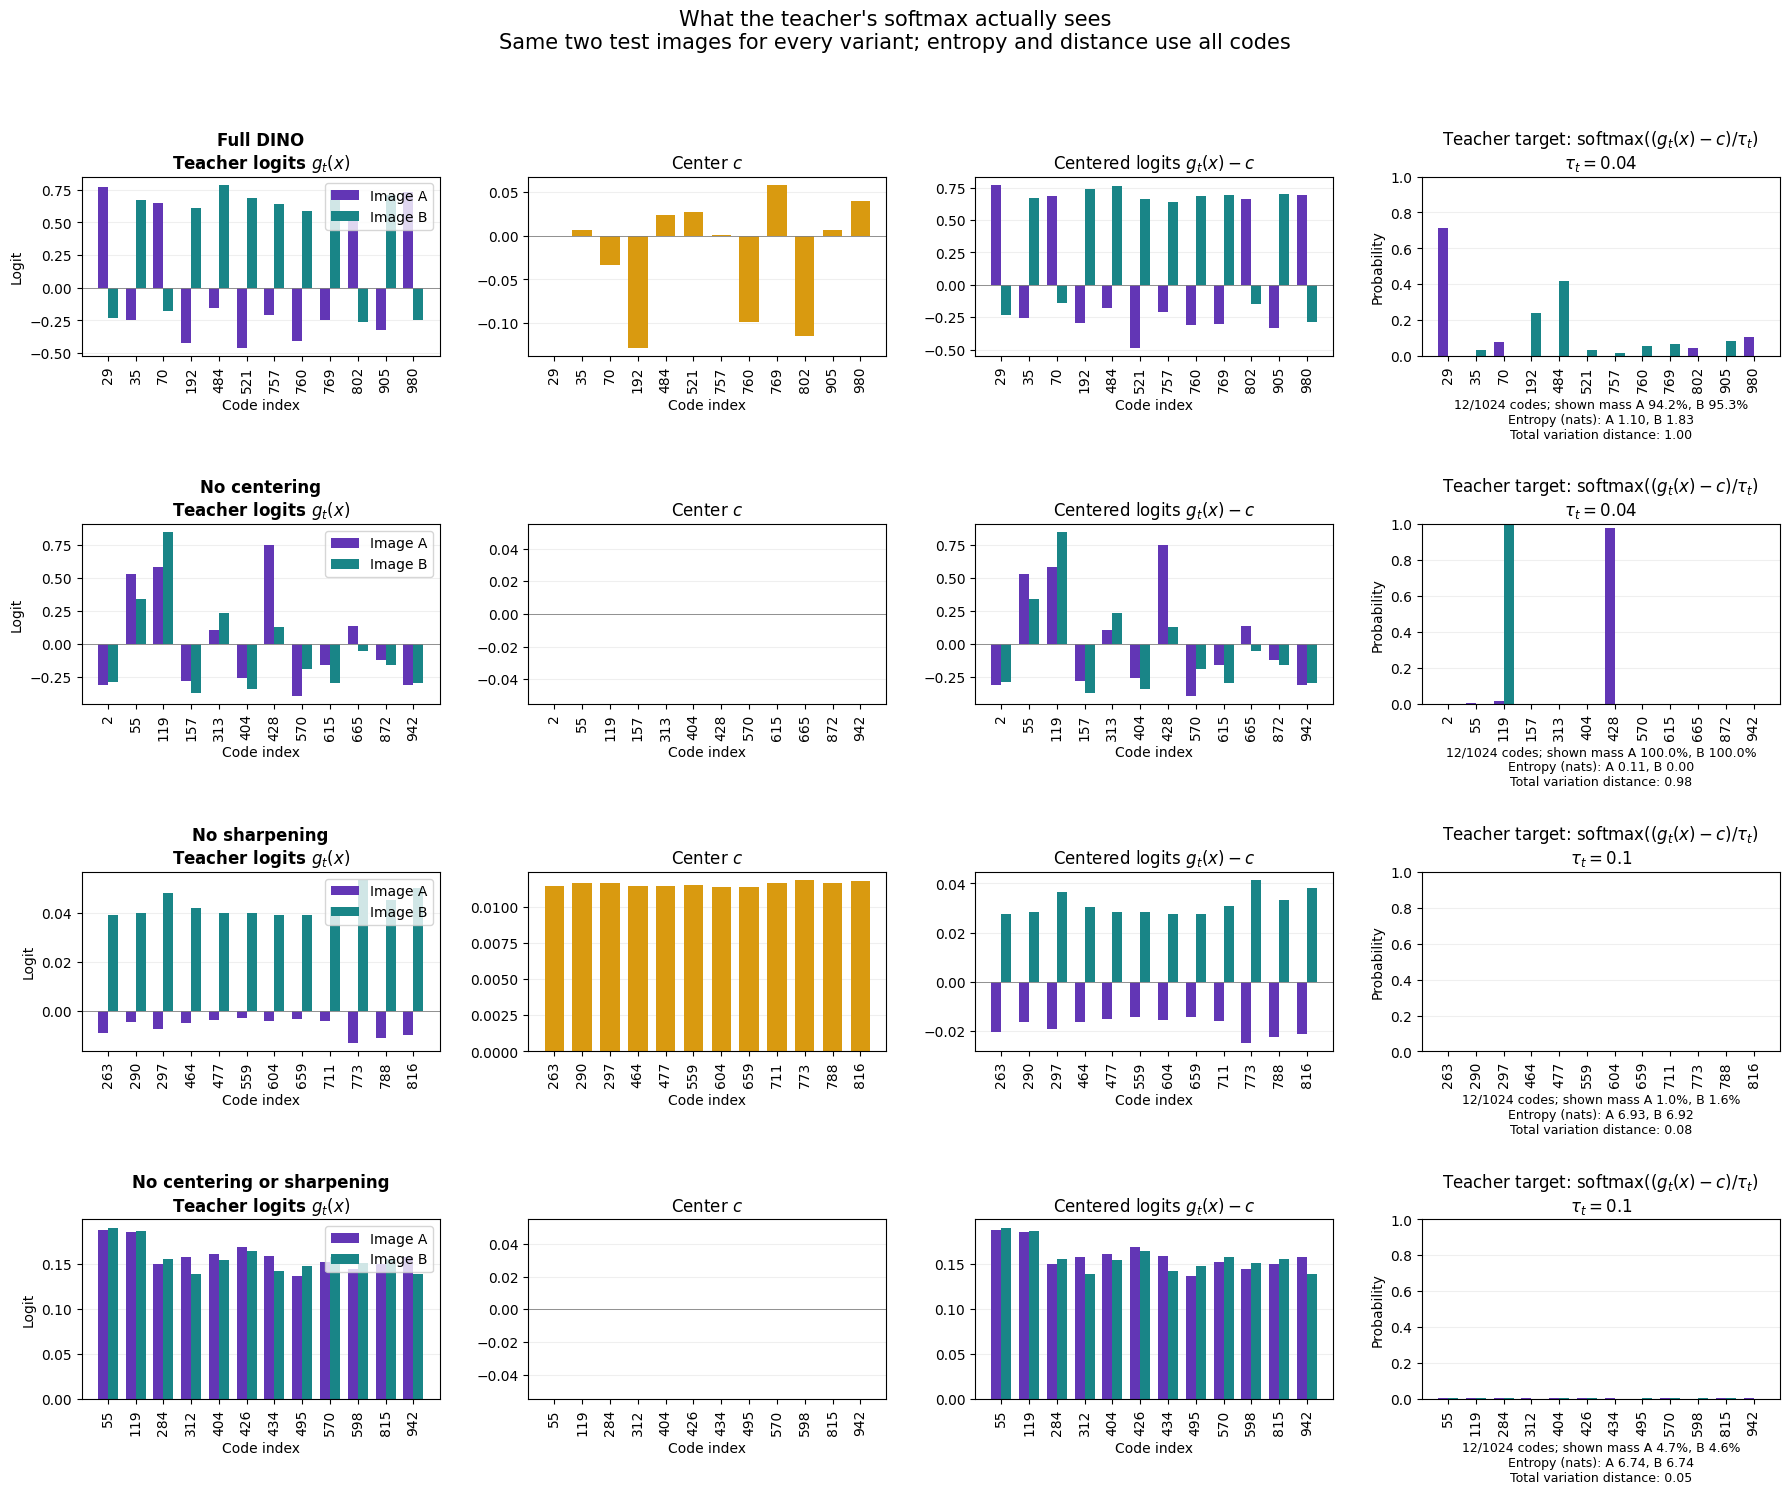

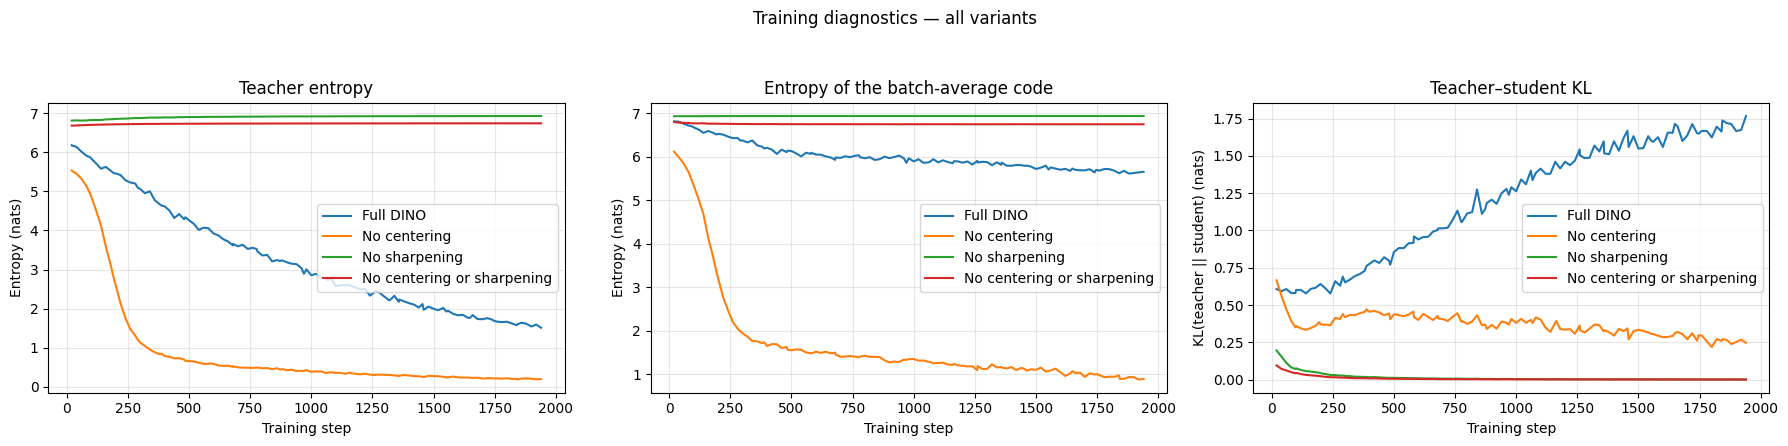

In [13]:
variants = {
    "Full DINO": full,
    "No centering": no_center,
    "No sharpening": no_sharpen,
    "No centering or sharpening": no_center_and_no_sharpen,
}
targets_fig, training_fig = plot_variants(variants, normalize(test_images[:2]))

# Save each figure explicitly before displaying it.
targets_fig.savefig("teacher-softmax-stages.png", dpi=300, bbox_inches="tight")
training_fig.savefig("entropy-and-teacher-student-KL.png", dpi=300, bbox_inches="tight")
plt.show()

## Part 2: your own way to prevent collapse
Implement your training changes in `training.py`, keeping the prescribed network,
fixed evaluation, and budget of at most 20 epochs per run.

---
Notes for the experiment runners: \
Run only the setup cells above the Part 1 (with according adjustments) and cell with your experiment.

It tunes on seed 0 with `val_knn`, runs the best configuration on seeds 0, 1, 2 with `knn_eval`, and saves everything to `/content/drive/MyDrive/dino_task4`.
After a disconnect, run it again: finished runs are loaded, not retrained.

### Fix nr. 1: standardization

In [14]:
%run fix_standardize.py

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Starting Person 2 tuning grid (six configurations, seed 0).

===== Evaluating standardize_scalar_tau0.08_K1024 =====
epoch  1 (  12s): entropy 0.32, batch entropy 3.15, KL 2.707
epoch  2 (  24s): entropy 0.24, batch entropy 3.05, KL 2.088
epoch  3 (  36s): entropy 0.25, batch entropy 3.16, KL 1.958
epoch  4 (  48s): entropy 0.31, batch entropy 3.36, KL 1.912
epoch  5 (  61s): entropy 0.32, batch entropy 3.50, KL 1.797, val_knn 0.3596
epoch  6 (  73s): entropy 0.33, batch entropy 3.54, KL 1.905
epoch  7 (  85s): entropy 0.31, batch entropy 3.59, KL 1.838
epoch  8 (  97s): entropy 0.38, batch entropy 3.66, KL 1.749
epoch  9 ( 109s): entropy 0.32, batch entropy 3.66, KL 1.757
epoch 10 ( 122s): entropy 0.28, batch entropy 3.66, KL 1.698, val_knn 0.3938
epoch 11 ( 134s): entropy 0.31, batch entropy 3.72, KL 1.708
epoch 12 ( 146s): entropy 0.32, batch entropy 3.73,

<Figure size 640x480 with 0 Axes>

### Fix nr. 2: mutual-information fix

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
epoch  1 (  12s): entropy 6.52, batch entropy 6.73, KL 0.224
epoch  2 (  24s): entropy 6.63, batch entropy 6.81, KL 0.151
epoch  3 (  36s): entropy 6.72, batch entropy 6.85, KL 0.099
epoch  4 (  48s): entropy 6.77, batch entropy 6.88, KL 0.070
epoch  5 (  62s): entropy 6.81, batch entropy 6.89, KL 0.048, val_knn 0.3406
epoch  6 (  73s): entropy 6.83, batch entropy 6.91, KL 0.040
epoch  7 (  85s): entropy 6.84, batch entropy 6.92, KL 0.031
epoch  8 (  97s): entropy 6.85, batch entropy 6.92, KL 0.026
epoch  9 ( 109s): entropy 6.86, batch entropy 6.92, KL 0.023
epoch 10 ( 123s): entropy 6.86, batch entropy 6.93, KL 0.021, val_knn 0.3482
epoch 11 ( 135s): entropy 6.87, batch entropy 6.93, KL 0.016
epoch 12 ( 147s): entropy 6.88, batch entropy 6.93, KL 0.018
epoch 13 ( 159s): entropy 6.88, batch entropy 6.93, KL 0.014
epoch 14 ( 171s): entropy 6.88, batch entropy 

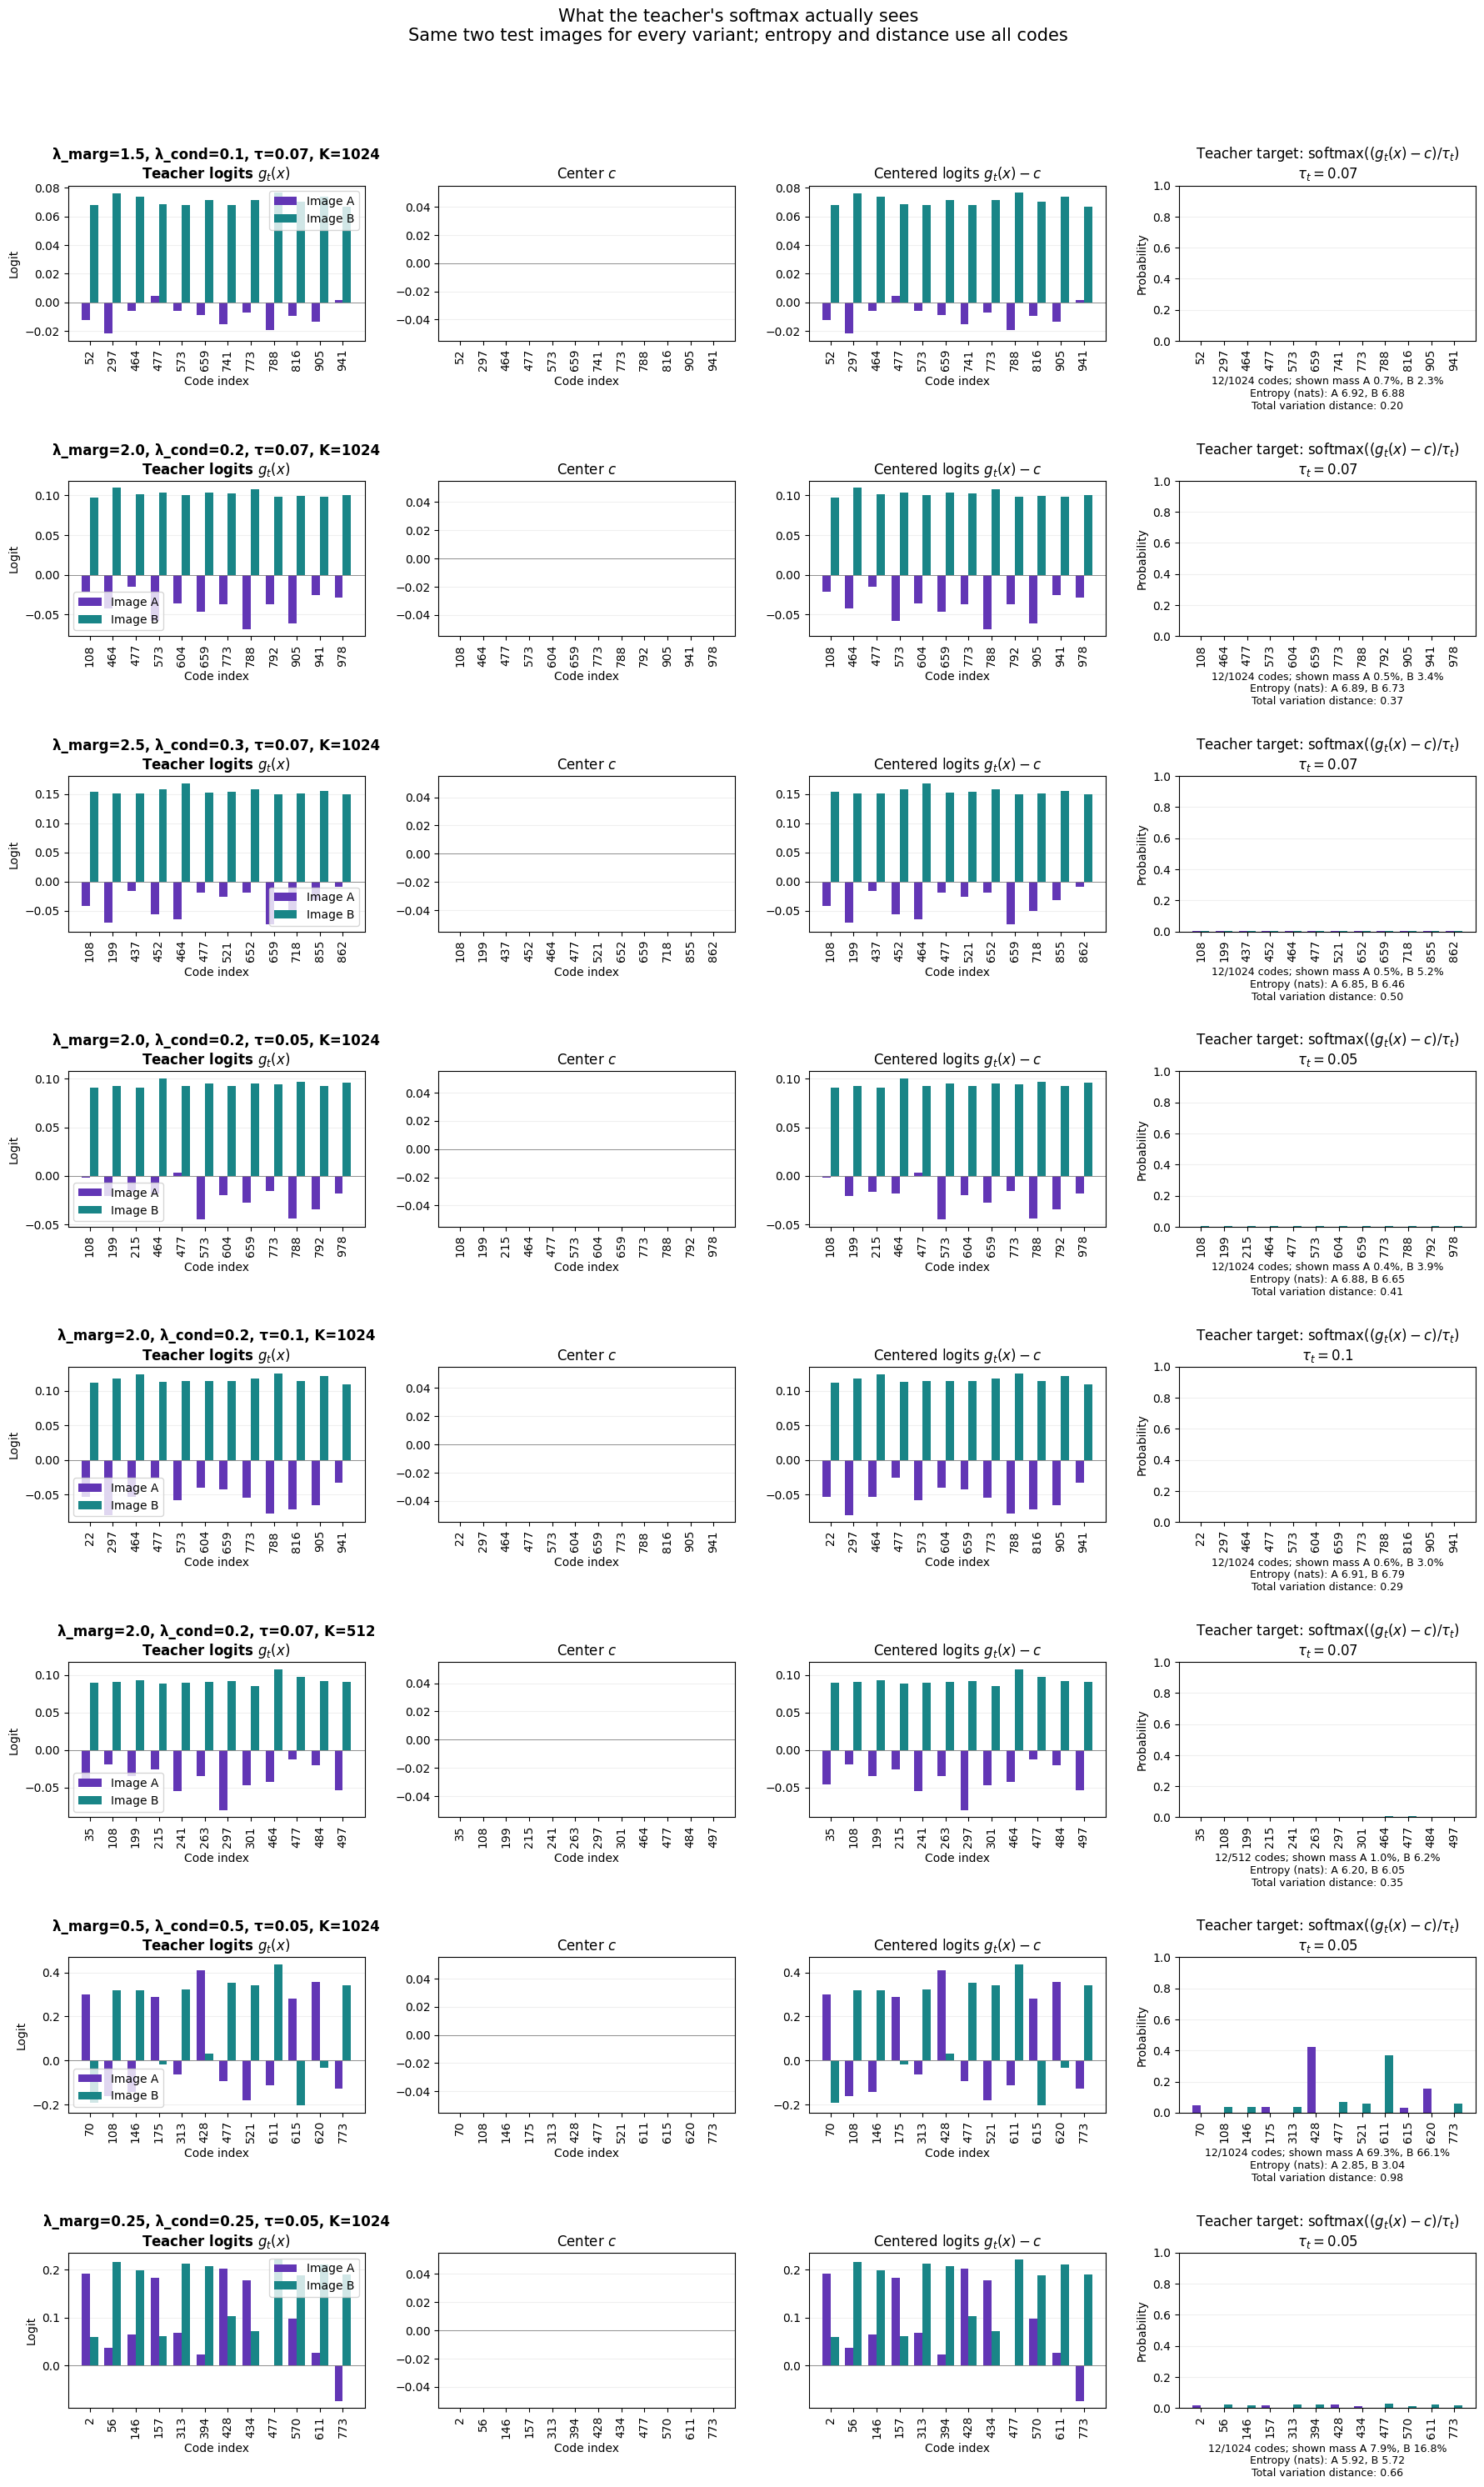

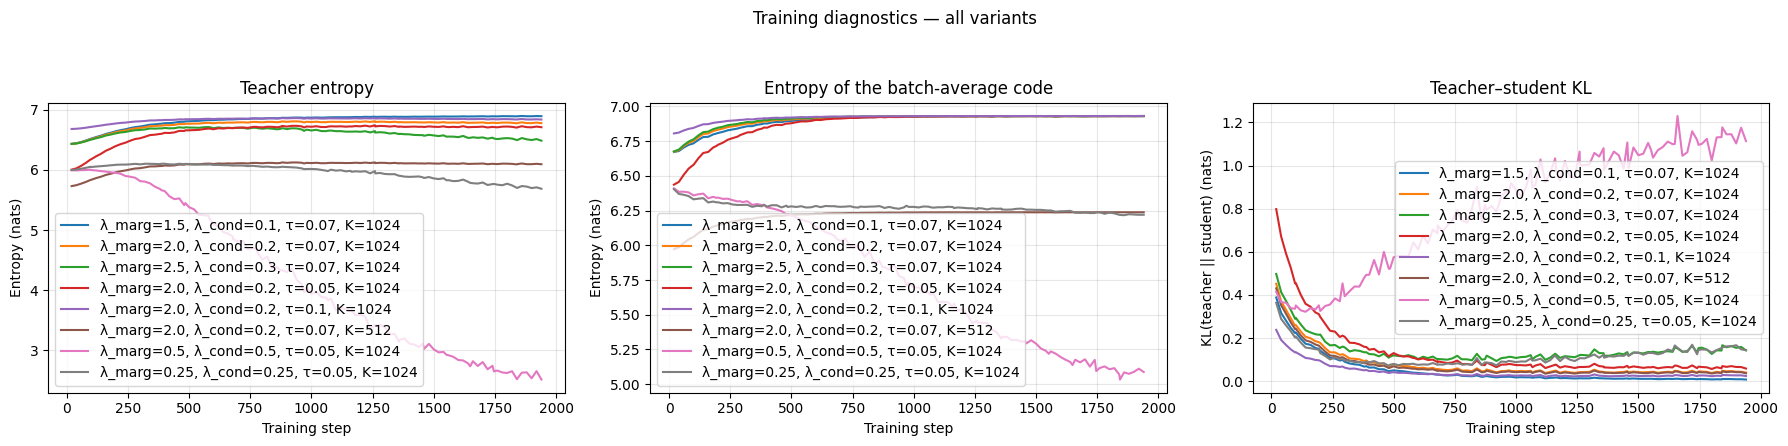

<Figure size 640x480 with 0 Axes>

In [15]:
%run fix_mutual_info.py